<a href="https://colab.research.google.com/github/Dan2222001/CS470-image-quality-project/blob/main/CS470_image_quality_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Imports and Google Drive Setup

To get this to work, follow these steps:
1. Open your Google Drive (Both your personal and university accounts should have the files)
2. Find the "vizwiz" folder in the "Shared with me" tab
3. Right click the vizwiz folder and press "Organize", then "Add Shortcut"
4. Select "My Drive" and add it as a shortcut

The first code block should say: "Folder exists: True" if you did it right.

In [ ]:
# Imports
import json
from pathlib import Path
from collections import Counter
import shutil

import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms, models

from dotenv import load_dotenv, find_dotenv
import os
load_dotenv(find_dotenv(usecwd=True))

#checking if running locally
try:
    from google.colab import drive

    # Opening Folder From Drive
    drive.mount("/content/drive")
except ImportError:
    print("Running locally")
    pass

# env vars
DATA = os.getenv("DATA_PATH")
print(DATA)


Running locally
C:\Users\kevin\image quality\vizwiz
c:\Users\kevin\image quality\CS470-image-quality-project


Checking which device the collab is running

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (f"Version: {torch.__version__}")
print (f"GPU Ready: {torch.cuda.is_available()}")
print (f"Selected device: {device}")
if device.type == "cuda":
    print (f"Device Name: {torch.cuda.get_device_name(0)}")

Version: 2.11.0+cu128
GPU Ready: True
Selected device: cuda
Device Name: NVIDIA GeForce RTX 3060


###Testing Google Drive Connection with Opening Annotations - This part is mainly just seeing what the data is like and how to display it

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = Path("/content/drive/MyDrive/vizwiz")     
    IN_COLAB = True
except ImportError:
    DATA = Path(os.getenv("DATA_PATH"))  
    IN_COLAB = False

print("Data folder:", DATA, "| exists:", DATA.exists())

Data folder: C:\Users\kevin\image quality\vizwiz | exists: True


In [4]:
folder = DATA / "annotations"
print("Folder exists:", folder.exists())

for file in folder.iterdir():
    print(file.name)

with open(folder / "train.json", "r") as f:
    train_data = json.load(f)

print("Number of images:", len(train_data))
print("First annotation:", train_data[0])
    


Folder exists: True
test.json
train.json
val.json
Number of images: 23431
First annotation: {'flaws': {'FRM': 1, 'BLR': 5, 'DRK': 0, 'BRT': 3, 'OBS': 0, 'OTH': 0, 'NON': 0, 'ROT': 0}, 'image': 'VizWiz_train_00022585.jpg', 'unrecognizable': 4}


0 votes: 15751 images
1 votes: 4122 images
2 votes: 1424 images
3 votes: 878 images
4 votes: 725 images
5 votes: 531 images


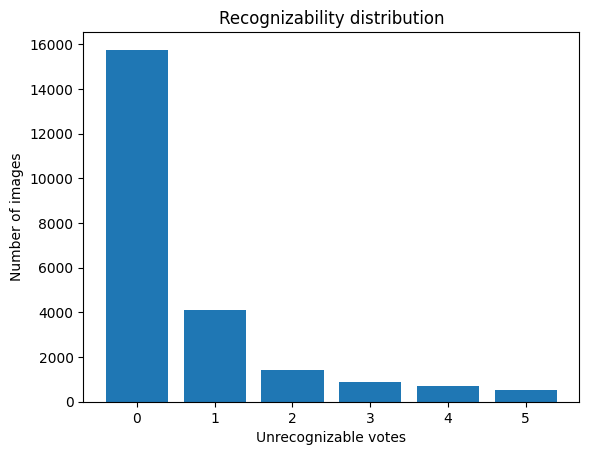

In [5]:
#Printing data distributions for unrecognizability
votes = Counter(
    item["unrecognizable"]
    for item in train_data
)

for count in range(6):
    print(f"{count} votes: {votes[count]} images")

plt.bar(range(6), [votes[i] for i in range(6)])

plt.xlabel("Unrecognizable votes")
plt.ylabel("Number of images")
plt.title("Recognizability distribution")
plt.show()

{'FRM': 1, 'BLR': 5, 'DRK': 0, 'BRT': 3, 'OBS': 0, 'OTH': 0, 'NON': 0, 'ROT': 0}


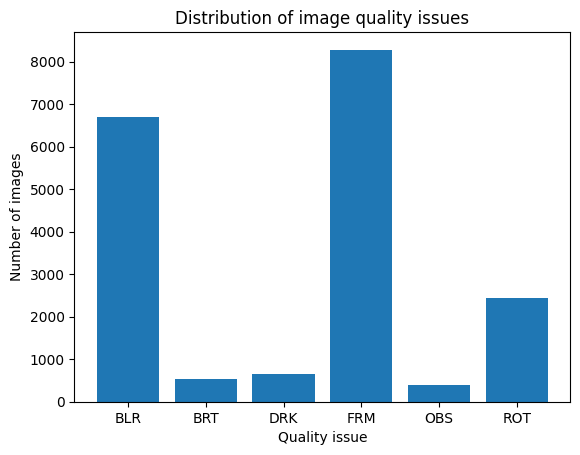

In [6]:
#Printing specific image flaw distribution where values >= 3 means that the flaw is present
print(train_data[0]["flaws"])
flaws = ["BLR", "BRT", "DRK", "FRM", "OBS", "ROT"]

flaw_counts = {
    flaw: sum(item["flaws"][flaw] >= 3 for item in train_data)
    for flaw in flaws
}

plt.bar(flaw_counts.keys(), flaw_counts.values())
plt.xlabel("Quality issue")
plt.ylabel("Number of images")
plt.title("Distribution of image quality issues")
plt.show()

Class for the flaw types

In [7]:
LABELS = ["BLR","BRT","DRK","FRM","OBS","OTH","NON","ROT"]

class VizWizQuality (Dataset):

    def __init__ (self, json_path, img_dir, transform):
        self.items = json.load(open(json_path))
        self.img_dir = Path(img_dir)
        self.transform =  transform

    def __len__ (self): return len(self.items)

    def __getitem__ (self, i):
        it = self.items[i]
        img = Image.open (self.img_dir / it["image"]).convert("RGB")
        x = self.transform(img)

        # checking if there is no data label, then return the filename
        if "flaws" not in it:
            return x, it["image"]

        y = [it["flaws"][k] / 5 for k in LABELS] + [it["unrecognizable"] / 5]
        return x, torch.tensor (y, dtype = torch.float32)


Copying the content from Drive to /content

DO NOT RUN THIS

In [8]:
if IN_COLAB:
    source = Path("/content/drive/MyDrive/vizwiz")
    destination = Path("/content/vizwiz")

    if not source.is_dir():
        raise FileNotFoundError(
            "The vizwiz folder was not found. Add a shortcut to it in My Drive."
        )

    
    print("Copying the dataset... Please wait.")
    shutil.copytree(source, destination, dirs_exist_ok=True)
    print("Done! Files are available at /content/vizwiz")
else:
    print ("Using local data")

Using local data


Transforming the images to 224 x 224

In [9]:
from torchvision.models import ResNet18_Weights
print(ResNet18_Weights.DEFAULT.transforms())

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [11]:
model_weights = ResNet18_Weights.DEFAULT

ORIGINAL_MEAN = model_weights.transforms().mean
ORIGINAL_STD = model_weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(ORIGINAL_MEAN,ORIGINAL_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(ORIGINAL_MEAN, ORIGINAL_STD)
])

Creating the dataset for the model to train on

In [12]:
ANNOTATIONS = DATA / "annotations"
IMG = DATA / "images"

train_dataset = VizWizQuality(ANNOTATIONS / "train.json", IMG / "train", train_transform)
val_dataset = VizWizQuality(ANNOTATIONS / "val.json", IMG / "val", eval_transform)
test_dataset = VizWizQuality(ANNOTATIONS / "test.json", IMG / "test", eval_transform)

print (f"Train dataset size:", len(train_dataset))
print (f"Val dataset size:", len(val_dataset))
print (f"Test dataset size:", len(test_dataset))

x, y = train_dataset[0]
print (x.shape, y)

Train dataset size: 23431
Val dataset size: 7750
Test dataset size: 8000
torch.Size([3, 224, 224]) tensor([1.0000, 0.6000, 0.0000, 0.2000, 0.0000, 0.0000, 0.0000, 0.0000, 0.8000])


Dataloaders

In [13]:
BATCH_SIZE = 64
loader_args = dict( batch_size = BATCH_SIZE, num_workers = 0, pin_memory = (device.type == "cuda"))

train_loader = DataLoader (train_dataset, shuffle = True, **loader_args)
val_loader = DataLoader (val_dataset, shuffle = False, **loader_args)
test_loader = DataLoader (test_dataset, shuffle = False, **loader_args)

x, y = next(iter(train_loader))
print (x.shape, y.shape)

torch.Size([64, 3, 224, 224]) torch.Size([64, 9])


Loading in ResNet18 and adjuisting the output

In [14]:
# orginal model
model = models.resnet18(model_weights)
print (model.fc)

# model adjusted to our purpose
model.fc = nn.Linear(model.fc.in_features, len(LABELS) + 1)
model = model.to(device)
print (model.fc)

Linear(in_features=512, out_features=1000, bias=True)
Linear(in_features=512, out_features=9, bias=True)


c:\Users\kevin\miniconda3\envs\ai\lib\site-packages\torchvision\models\_utils.py:135: UserWarning: Using 'weights' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(


Preliminary evaluation of the model

In [15]:
from tqdm.auto import tqdm

criterion = nn.BCEWithLogitsLoss()

print("starting eval")

def evaluate (model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    correct = torch.zeros(len(LABELS) + 1)
    always_no = torch.zeros(len(LABELS) + 1)

    with torch.no_grad():
        for x, y in tqdm(loader, desc = "Evaluating"):
            x, y = x.to(device), y.to(device)
            logits = model (x)
            total_loss += criterion(logits, y).item() * x.size(0)  # returns the average loss of this batch

            preds = torch.sigmoid(logits) > 0.5  # threshold for if a flaw exist
            truth = y > 0.6 # if 3 or more agreed on the flaw
            correct += (preds == truth).sum(dim=0).cpu()
            always_no += (~truth).sum(dim=0).cpu()
            n += x.size(0)

        return total_loss / n, correct / n, always_no / n

val_loss, val_acc, baseline_acc = evaluate(model, val_loader)
print(f"val loss: {val_loss:.4f}")
for name, a, b in zip(LABELS + ["UNREC"], val_acc, baseline_acc):
    print(f"{name:6} model acc: {a:.3f}   always-'no' acc: {b:.3f}")


starting eval


Evaluating:   0%|          | 0/122 [00:00<?, ?it/s]

val loss: 0.7058
BLR    model acc: 0.698   always-'no' acc: 0.807
BRT    model acc: 0.700   always-'no' acc: 0.990
DRK    model acc: 0.515   always-'no' acc: 0.983
FRM    model acc: 0.779   always-'no' acc: 0.820
OBS    model acc: 0.452   always-'no' acc: 0.994
OTH    model acc: 0.788   always-'no' acc: 1.000
NON    model acc: 0.578   always-'no' acc: 0.828
ROT    model acc: 0.127   always-'no' acc: 0.951
UNREC  model acc: 0.469   always-'no' acc: 0.940
